Training data: (27455, 28, 28, 1)
Testing data: (7172, 28, 28, 1)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)                    │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 24)                  │           3,096 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 226,840 (886.09 KB)

 Trainable params: 226,840 (886.09 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 30s 69ms/step - accuracy: 0.6691 - loss: 1.1566 - val_accuracy: 0.9301 - val_loss: 0.2807
Epoch 2/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 16s 40ms/step - accuracy: 0.9776 - loss: 0.1130 - val_accuracy: 0.9985 - val_loss: 0.0300
Epoch 3/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 16s 42ms/step - accuracy: 0.9989 - loss: 0.0207 - val_accuracy: 0.9993 - val_loss: 0.0133
Epoch 4/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 13s 33ms/step - accuracy: 0.9998 - loss: 0.0067 - val_accuracy: 1.0000 - val_loss: 0.0035
Epoch 5/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 12s 32ms/step - accuracy: 0.9999 - loss: 0.0033 - val_accuracy: 1.0000 - val_loss: 0.0019
Epoch 6/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - accuracy: 1.0000 - loss: 0.0020 - val_accuracy: 1.0000 - val_loss: 0.0014
Epoch 7/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 13s 34ms/step - accuracy: 0.9943 - loss: 0.0189 - val_accuracy: 1.0000 - val_loss: 0.0012
Epoch 8/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - accuracy: 1.0000 - loss: 8.5969e-0

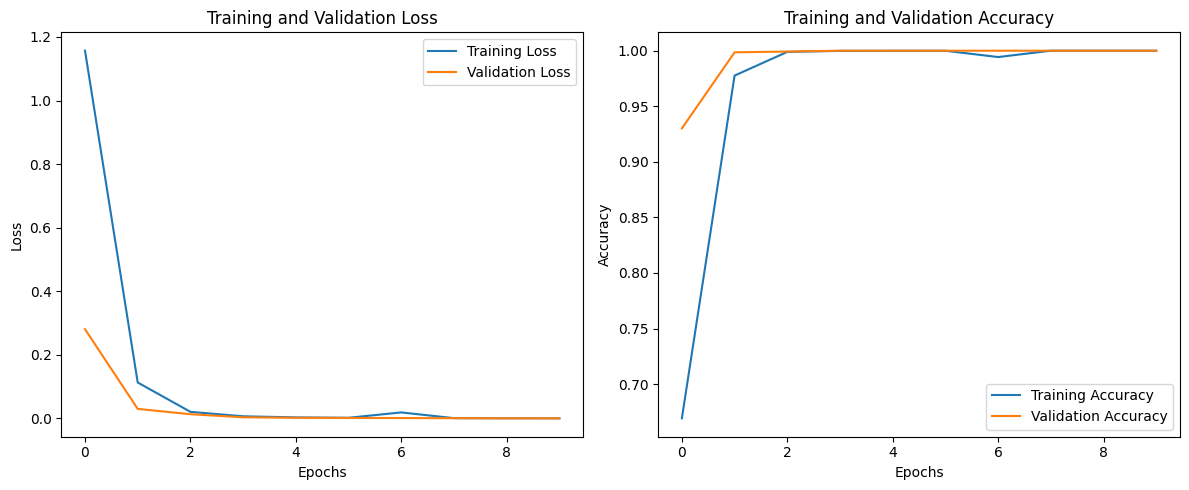

In [4]:

# Practical 2C: CNN for Sign Language MNIST Classification

# a. Loading and preprocessing the image data

# Import necessary packages
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense

# Load training and testing data
train_data = pd.read_csv(r'D:\Downloads\LP IV Updated Datasets\LP IV Updated Datasets\FNN and CNN\Sign Language MNIST\sign_mnist_train.csv')
test_data = pd.read_csv(r'D:\Downloads\LP IV Updated Datasets\LP IV Updated Datasets\FNN and CNN\Sign Language MNIST\sign_mnist_test.csv')

# Separate features and labels
X_train = train_data.drop('label', axis=1).values
y_train = train_data['label'].values

X_test = test_data.drop('label', axis=1).values
y_test = test_data['label'].values

# Convert labels from 0-24 (excluding 9) to 0-23
y_train = np.where(y_train > 9, y_train - 1, y_train)
y_test = np.where(y_test > 9, y_test - 1, y_test)

# Normalize pixel values
X_train = X_train / 255.0
X_test = X_test / 255.0

# Reshape images into 28x28 with 1 channel
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

# b. Defining the model's architecture

model = Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation='relu'),

    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),

    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation='relu'),

    Dense(24, activation='softmax')
])

# Display model architecture
model.summary()

# c. Training the model

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

# d. Estimating the model's performance

loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

# Plot training loss and accuracy
plt.figure(figsize=(12, 5))

# Training and validation loss
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Training and validation accuracy
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()


225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step


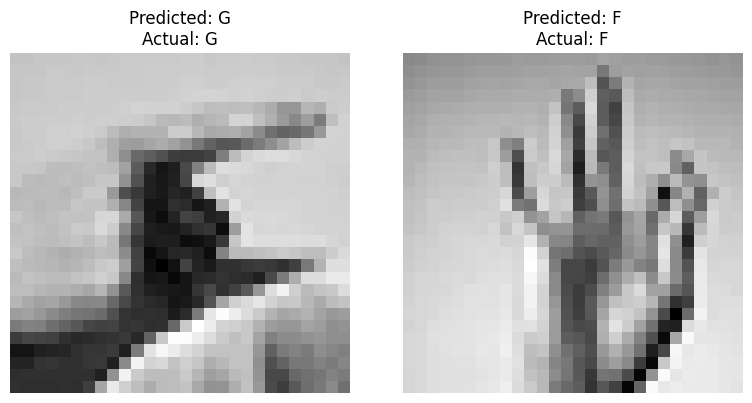

In [5]:
# Display 2 sample predictions
class_names = list("ABCDEFGHIKLMNOPQRSTUVWXY")

predictions = model.predict(X_test)
predicted_labels = predictions.argmax(axis=1)

plt.figure(figsize=(8, 4))

for i in range(2):
    plt.subplot(1, 2, i+1)

    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')

    plt.title("Predicted: " + class_names[predicted_labels[i]] +
              "\nActual: " + class_names[y_test[i]])

    plt.axis('off')

plt.tight_layout()
plt.show()